<a href="https://colab.research.google.com/github/madeeha-noor/BERT-Fine-Tuning-Reproduction/blob/main/P09_BERT_Week8.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import torch
import random
import numpy as np

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("PyTorch:", torch.__version__)
print("Device:", device)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

PyTorch: 2.11.0+cu130
Device: cuda
GPU: Tesla T4


In [ ]:
!pip -q install transformers datasets

In [ ]:

from datasets import load_dataset
from transformers import AutoTokenizer, AutoModelForSequenceClassification

# Load the SST-2 dataset
dataset = load_dataset("nyu-mll/glue", "sst2")

# Load BERT tokenizer
tokenizer = AutoTokenizer.from_pretrained("bert-base-uncased")

print("Training examples:", len(dataset["train"]))
print("Validation examples:", len(dataset["validation"]))
print(dataset["train"][0])

print("SST-2 dataset loaded successfully!")


README.md:   0%|          | 0.00/35.3k [00:00<?, ?B/s]

sst2/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 3.11MB            

sst2/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

sst2/validation-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 72.8kB            

sst2/validation-00000-of-00001.parquet: downloading bytes:           |  0.00B            

...

Generating test split:   0%|          | 0/1821 [00:00<?, ? examples/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

Training examples: 67349
Validation examples: 872
{'sentence': 'hide new secretions from the parental units ', 'label': 0, 'idx': 0}
SST-2 dataset loaded successfully!


In [ ]:
def tokenize_data(batch):
    return tokenizer(
        batch["sentence"],
        padding="max_length",
        truncation=True,
        max_length=128
    )

tokenized = dataset.map(
    tokenize_data,
    batched=True
)

tokenized = tokenized.rename_column("label", "labels")

print(tokenized["train"][0].keys())

Map:   0%|          | 0/67349 [00:00<?, ? examples/s]

Map:   0%|          | 0/872 [00:00<?, ? examples/s]

Map:   0%|          | 0/1821 [00:00<?, ? examples/s]

dict_keys(['sentence', 'labels', 'idx', 'input_ids', 'token_type_ids', 'attention_mask'])


In [ ]:
from torch.utils.data import DataLoader

train_data = tokenized["train"].select(range(4000))
val_data = tokenized["validation"]

columns = ["input_ids", "attention_mask", "labels"]

train_data.set_format("torch", columns=columns)
val_data.set_format("torch", columns=columns)

train_loader = DataLoader(
    train_data,
    batch_size=16,
    shuffle=True
)

val_loader = DataLoader(
    val_data,
    batch_size=32,
    shuffle=False
)

print("Training examples:", len(train_data))
print("Validation examples:", len(val_data))
print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))

Training examples: 4000
Validation examples: 872
Training batches: 250
Validation batches: 28


In [ ]:
model = AutoModelForSequenceClassification.from_pretrained(
    "bert-base-uncased",
    num_labels=2
).to(device)

print("BERT model loaded successfully!")

model.safetensors: reconstructing file:   0%|          |  0.00B /  440MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


BERT model loaded successfully!


In [ ]:
batch = next(iter(train_loader))

for key, value in batch.items():
    print(key, value.shape, value.dtype)

assert batch["input_ids"].shape == (16, 128)
assert batch["attention_mask"].shape == (16, 128)
assert batch["labels"].shape == (16,)

print("Batch shapes verified!")

labels torch.Size([16]) torch.int64
input_ids torch.Size([16, 128]) torch.int64
attention_mask torch.Size([16, 128]) torch.int64
Batch shapes verified!


In [ ]:
model.eval()

with torch.no_grad():
    inputs = {
        "input_ids": batch["input_ids"].to(device),
        "attention_mask": batch["attention_mask"].to(device)
    }

    output = model(**inputs)

print("Output shape:", output.logits.shape)

assert output.logits.shape == (16, 2)

print("Model output verified!")

Output shape: torch.Size([16, 2])
Model output verified!


In [ ]:
label_names = {
    0: "Negative",
    1: "Positive"
}

for i in range(5):
    row = train_data[i]

    sentence = tokenizer.decode(
        row["input_ids"],
        skip_special_tokens=True
    )

    label = row["labels"].item()

    print("Sentence:", sentence)
    print("Sentiment:", label_names[label])
    print()

Sentence: hide new secretions from the parental units
Sentiment: Negative

Sentence: contains no wit, only labored gags
Sentiment: Negative

Sentence: that loves its characters and communicates something rather beautiful about human nature
Sentiment: Positive

Sentence: remains utterly satisfied to remain the same throughout
Sentiment: Negative

Sentence: on the worst revenge - of - the - nerds cliches the filmmakers could dredge up
Sentiment: Negative



In [ ]:
layer = model.bert.encoder.layer[0]

actual_params = sum(
    p.numel() for p in layer.parameters()
)

print("Hand calculation:", 7087872)
print("PyTorch count:", actual_params)

assert actual_params == 7087872

print("Parameter count verified!")

Hand calculation: 7087872
PyTorch count: 7087872
Parameter count verified!


Step 0: Loss = 0.6896
Step 10: Loss = 0.3850
Step 20: Loss = 0.1394
Step 30: Loss = 0.0648
Step 40: Loss = 0.0278
Step 50: Loss = 0.0150


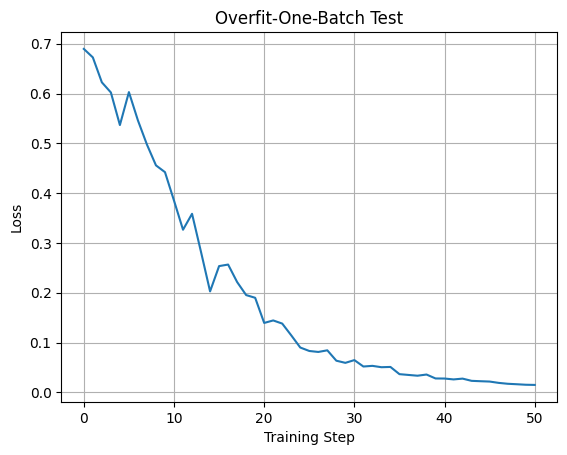

In [ ]:
import matplotlib.pyplot as plt

small_batch = next(iter(train_loader))

small_batch = {
    key: value[:8].to(device)
    for key, value in small_batch.items()
}

optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=2e-5
)

overfit_losses = []

for step in range(51):
    model.train()
    optimizer.zero_grad()

    output = model(
        input_ids=small_batch["input_ids"],
        attention_mask=small_batch["attention_mask"],
        labels=small_batch["labels"]
    )

    loss = output.loss
    loss.backward()
    optimizer.step()

    overfit_losses.append(loss.item())

    if step % 10 == 0:
        print(f"Step {step}: Loss = {loss.item():.4f}")

plt.plot(overfit_losses)
plt.xlabel("Training Step")
plt.ylabel("Loss")
plt.title("Overfit-One-Batch Test")
plt.grid(True)
plt.show()

In [ ]:
model = AutoModelForSequenceClassification.from_pretrained(
    "bert-base-uncased",
    num_labels=2
).to(device)

optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=2e-5
)

print("Fresh BERT model ready for baseline training!")

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Fresh BERT model ready for baseline training!


In [ ]:
def train_one_epoch(model, loader, optimizer):
    model.train()

    total_loss = 0
    total = 0

    for batch in loader:
        batch = {
            key: value.to(device)
            for key, value in batch.items()
        }

        optimizer.zero_grad()

        output = model(**batch)
        output.loss.backward()
        optimizer.step()

        total_loss += output.loss.item() * batch["labels"].size(0)
        total += batch["labels"].size(0)

    return total_loss / total


def evaluate(model, loader):
    model.eval()

    total_loss = 0
    correct = 0
    total = 0

    with torch.no_grad():
        for batch in loader:
            batch = {
                key: value.to(device)
                for key, value in batch.items()
            }

            output = model(**batch)

            total_loss += (
                output.loss.item() * batch["labels"].size(0)
            )

            predictions = output.logits.argmax(dim=1)

            correct += (
                predictions == batch["labels"]
            ).sum().item()

            total += batch["labels"].size(0)

    return total_loss / total, correct / total

In [ ]:
train_losses = []
val_losses = []
val_accuracies = []

for epoch in range(2):
    train_loss = train_one_epoch(
        model, train_loader, optimizer
    )

    val_loss, val_accuracy = evaluate(
        model, val_loader
    )

    train_losses.append(train_loss)
    val_losses.append(val_loss)
    val_accuracies.append(val_accuracy)

    print(
        f"Epoch {epoch + 1}: "
        f"Train Loss = {train_loss:.4f}, "
        f"Validation Loss = {val_loss:.4f}, "
        f"Validation Accuracy = {val_accuracy:.4f}"
    )

Epoch 1: Train Loss = 0.3862, Validation Loss = 0.2908, Validation Accuracy = 0.8773
Epoch 2: Train Loss = 0.1636, Validation Loss = 0.2740, Validation Accuracy = 0.8911


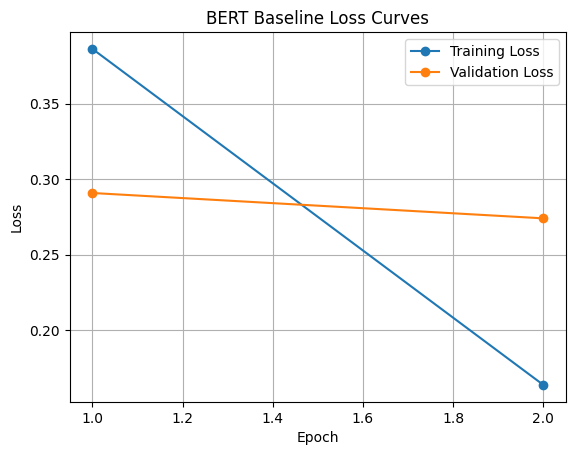

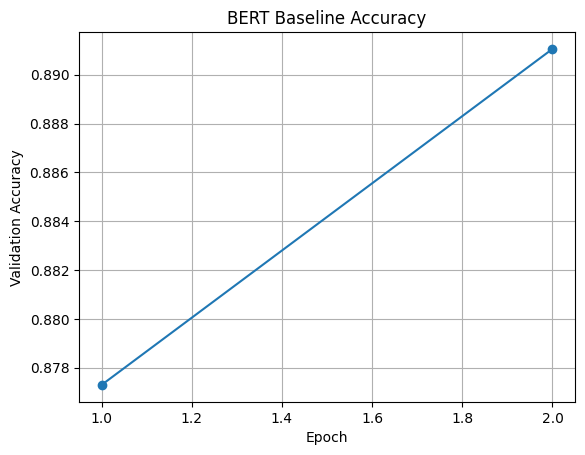

In [ ]:
epochs = range(1, len(train_losses) + 1)

plt.plot(epochs, train_losses, marker="o", label="Training Loss")
plt.plot(epochs, val_losses, marker="o", label="Validation Loss")

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("BERT Baseline Loss Curves")
plt.legend()
plt.grid(True)
plt.show()

plt.plot(epochs, val_accuracies, marker="o")

plt.xlabel("Epoch")
plt.ylabel("Validation Accuracy")
plt.title("BERT Baseline Accuracy")
plt.grid(True)
plt.show()

In [ ]:
torch.save(
    {
        "model_state_dict": model.state_dict(),
        "optimizer_state_dict": optimizer.state_dict(),
        "train_losses": train_losses,
        "val_losses": val_losses,
        "val_accuracies": val_accuracies
    },
    "bert_week8_checkpoint.pt"
)

print("Checkpoint saved!")

Checkpoint saved!
